# PAAD Xenium Analysis
Last updated: 9/1/2026

## Modules

In [ ]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import harmonypy as hm
import random
import scipy.sparse as sp

ModuleNotFoundError: No module named 'scanpy'

In [ ]:
random.seed(777)
np.random.seed(777)
sc.settings.random_state = 777

## Import Data
Loading in and merging three patients from the PAAD Xenium dataset from Donahue et al. 2026.

In [ ]:
patients = ["GSM9372001_Pt01", "GSM9372003_Pt09", "GSM9372002_Pt10", "GSM9372004_Pt11", "GSM9372005_Pt15", "GSM9372006_Pt20"]
adatas = {}

for name in patients:
    adata = sc.read_10x_h5(f"{name}_cell_feature_matrix.h5")
    adata.var_names_make_unique()

    cells_df = pd.read_parquet(f"{name}_cells.parquet")

    if "cell_id" in cells_df.columns:
        cells_df = cells_df.set_index("cell_id")

    cells_df_aligned = cells_df.reindex(adata.obs_names)

    adata.obsm["spatial"] = cells_df_aligned[["x_centroid", "y_centroid"]].to_numpy()
    adata.obs["cell_area"] = cells_df_aligned["cell_area"]

    adatas[name] = adata

In [ ]:
adata_merged = ad.concat(adatas, label="sample_id", merge = "same")
adata_merged.obs_names_make_unique()

C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\anndata\_core\anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


## Quality Control

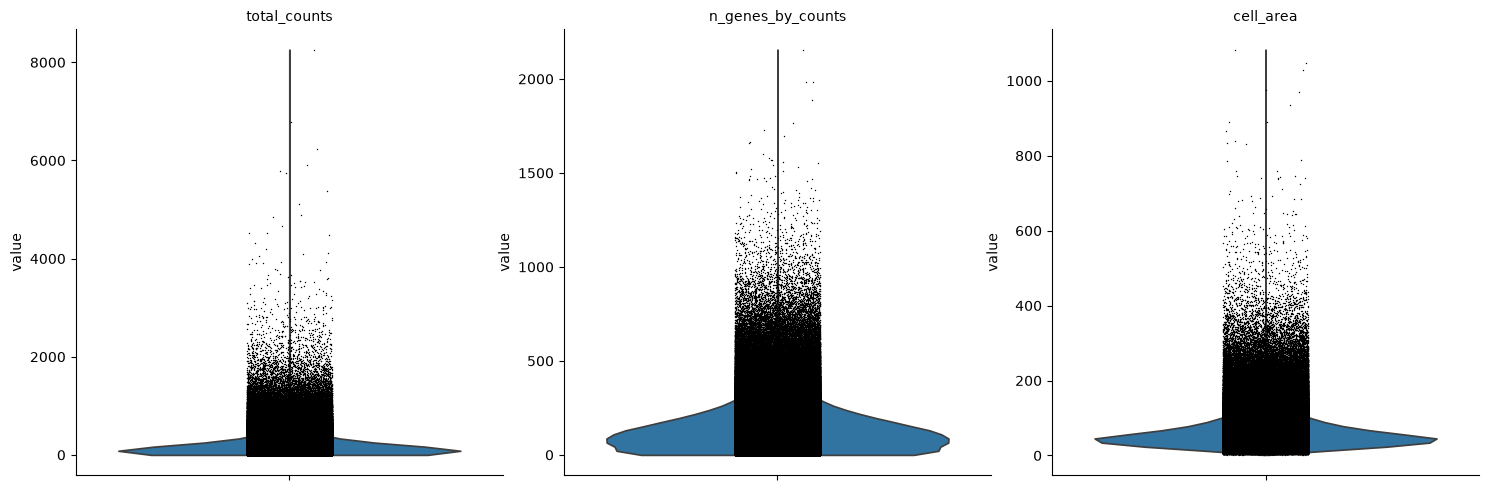

In [ ]:
# Calculate standard cell-level metrics
sc.pp.calculate_qc_metrics(adata_merged, percent_top=None, inplace=True)

# Plot distributions
sc.pl.violin(
    adata_merged,
    keys=["total_counts", "n_genes_by_counts", "cell_area"],
    multi_panel=True,
)

In [ ]:
# Apply basic cell filters
min_counts = 10
min_genes = 5

print("Unfiltered AnnData shape:", adata_merged.shape)

adata_merged = adata_merged[
    (adata_merged.obs["total_counts"] >= min_counts)
    & (adata_merged.obs["n_genes_by_counts"] >= min_genes)
].copy()

print("Filtered AnnData shape:", adata_merged.shape)

Unfiltered AnnData shape: (977823, 5101)
Filtered AnnData shape: (916891, 5101)


## Normalization

In [ ]:
# 1. Make sure all gene names are unique, remove genes with no expression
adata_merged.var_names_make_unique()
sc.pp.filter_genes(adata_merged, min_cells=1)

# 2. Preserve raw counts in a layer
adata_merged.layers["counts"] = adata_merged.X.copy()

# 3. Normalize and Log1p
sc.pp.normalize_total(adata_merged, target_sum=1e4)
sc.pp.log1p(adata_merged)

# 4 Find Highly Variable Genes
sc.pp.highly_variable_genes(adata_merged, n_top_genes=2000)

# 5. PCA
sc.pp.pca(adata_merged, random_state = 777)

# 6. Run Harmony
ho = hm.run_harmony(adata_merged.obsm['X_pca'], adata_merged.obs, 'sample_id', random_state = 777)
adata_merged.obsm['X_pca_harmony'] = ho.Z_corr.T if ho.Z_corr.shape[0] == 50 else ho.Z_corr

# 7. Compute neighbors using Harmony representation
sc.pp.neighbors(adata_merged, use_rep="X_pca_harmony", n_neighbors=15, n_pcs=30, random_state = 777)

# 8. Run UMAP
sc.tl.umap(adata_merged, random_state = 777)

# 9. Run Clustering
sc.tl.leiden(adata_merged, resolution=0.5, flavor="igraph", n_iterations=-1, directed=False, random_state = 777)

2026-08-11 12:40:41,476 - harmonypy - INFO - Running Harmony (PyTorch on cpu)
2026-08-11 12:40:41,476 - harmonypy - INFO -   Parameters:
2026-08-11 12:40:41,476 - harmonypy - INFO -     max_iter_harmony: 10
2026-08-11 12:40:41,478 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-11 12:40:41,478 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-11 12:40:41,478 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-11 12:40:41,479 - harmonypy - INFO -     nclust: 100
2026-08-11 12:40:41,479 - harmonypy - INFO -     block_size: 0.05
2026-08-11 12:40:41,479 - harmonypy - INFO -     lamb: [1. 1. 1. 1. 1. 1.]
2026-08-11 12:40:41,480 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2.]
2026-08-11 12:40:41,480 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-08-11 12:40:41,480 - harmonypy - INFO -     verbose: True
2026-08-11 12:40:41,482 - harmonypy - INFO -     random_state: 777
2026-08-11 12:40:41,482 - harmonypy - INFO -   Data: 50 PCs × 916891 cells
2026-08-11 12:4

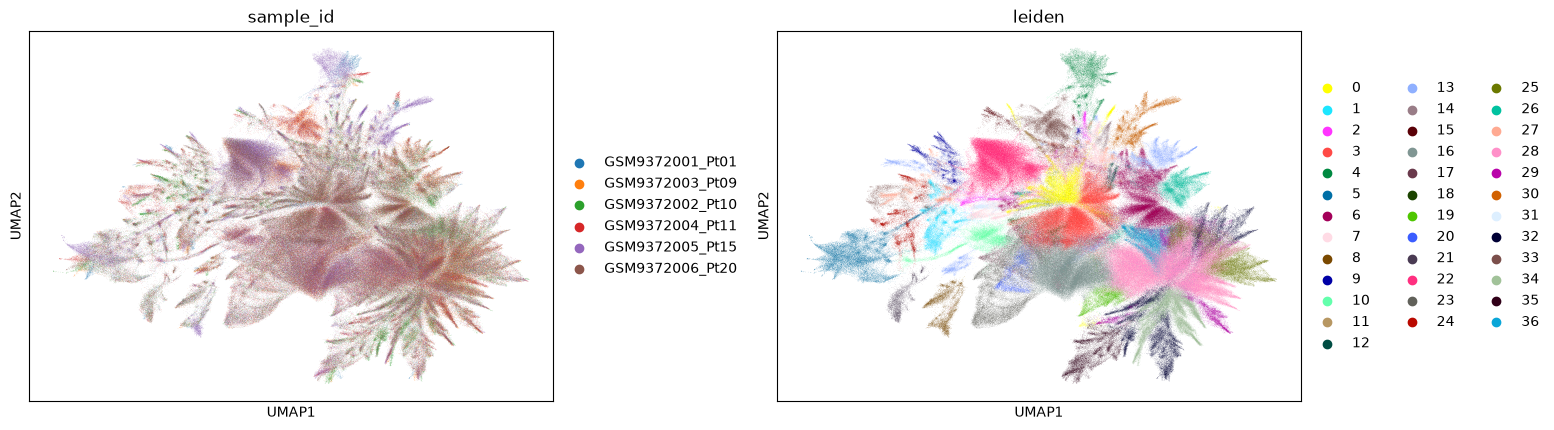

In [ ]:
sc.pl.umap(adata_merged, color=["sample_id", "leiden"], wspace=0.3)

## Cell Type Subsets

#### Endocrine (21)

In [ ]:
target_clusters = ['21']
adata_endocrine = adata_merged[adata_merged.obs['leiden'].isin(target_clusters)].copy()

In [ ]:
sc.pp.highly_variable_genes(adata_endocrine, n_top_genes=2000)
sc.pp.pca(adata_endocrine, random_state = 777)
sc.pp.neighbors(adata_endocrine, n_pcs=20, random_state = 777)
sc.tl.umap(adata_endocrine, random_state = 777)
sc.tl.leiden(adata_endocrine, flavor = "igraph", n_iterations = -1, directed = False, resolution=0.8, random_state = 777)

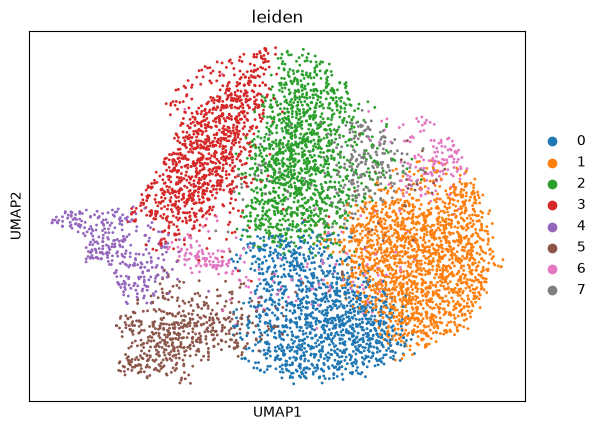

In [ ]:
sc.pl.umap(adata_endocrine, color="leiden", wspace=0.3)

Alpha: 1, 2, 6   
Beta: 0, 3, 5  
Unknown: 4, 8

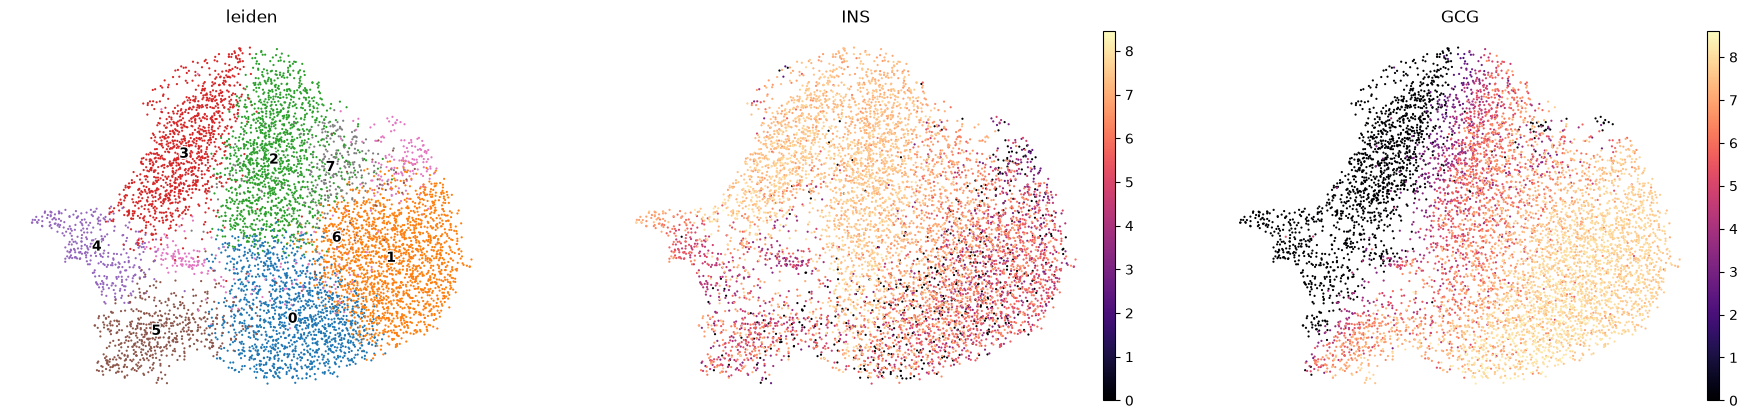

In [ ]:
genes_to_plot = ['INS', 'GCG']

genes_to_plot = [g for g in genes_to_plot if g in adata_endocrine.var_names]

plots_to_show = ["leiden"] + genes_to_plot

sc.pl.umap(
    adata_endocrine,
    color=plots_to_show,
    color_map="magma",
    ncols=3,
    size=10,
    frameon=False,
    legend_loc="on data",  # Works on panel 1 ('leiden')
    legend_fontoutline=2
)

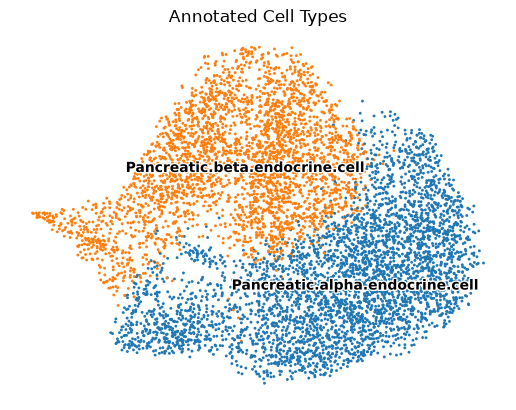

In [ ]:
# Map cluster numbers to cell type names
cluster_to_celltype = {
    '0': 'Pancreatic.alpha.endocrine.cell',
    '1': 'Pancreatic.alpha.endocrine.cell',
    '2': 'Pancreatic.beta.endocrine.cell',
    '3': 'Pancreatic.beta.endocrine.cell',
    '4': 'Pancreatic.beta.endocrine.cell',
    '5': 'Pancreatic.alpha.endocrine.cell',
    '6': 'Pancreatic.alpha.endocrine.cell',
    '7': 'Pancreatic.beta.endocrine.cell'
}

adata_endocrine.obs['cell_type'] = adata_endocrine.obs['leiden'].map(cluster_to_celltype)

adata_endocrine.obs['cell_type'] = adata_endocrine.obs['cell_type'].astype('category')

sc.pl.umap(
    adata_endocrine,
    color='cell_type',
    legend_loc='on data',
    legend_fontsize=10,
    legend_fontoutline=2,
    title='Annotated Cell Types',
    frameon=False
)

#### Endothelial (23)

In [ ]:
target_clusters = ['23']
adata_endothelial = adata_merged[adata_merged.obs['leiden'].isin(target_clusters)].copy()

In [ ]:
sc.pp.highly_variable_genes(adata_endothelial, n_top_genes=2000)
sc.pp.pca(adata_endothelial, random_state = 777)
sc.pp.neighbors(adata_endothelial, n_pcs=20, random_state = 777)
sc.tl.umap(adata_endothelial, random_state = 777)
sc.tl.leiden(adata_endothelial, flavor = "igraph", n_iterations = -1, directed = False, resolution=0.8, random_state = 777)

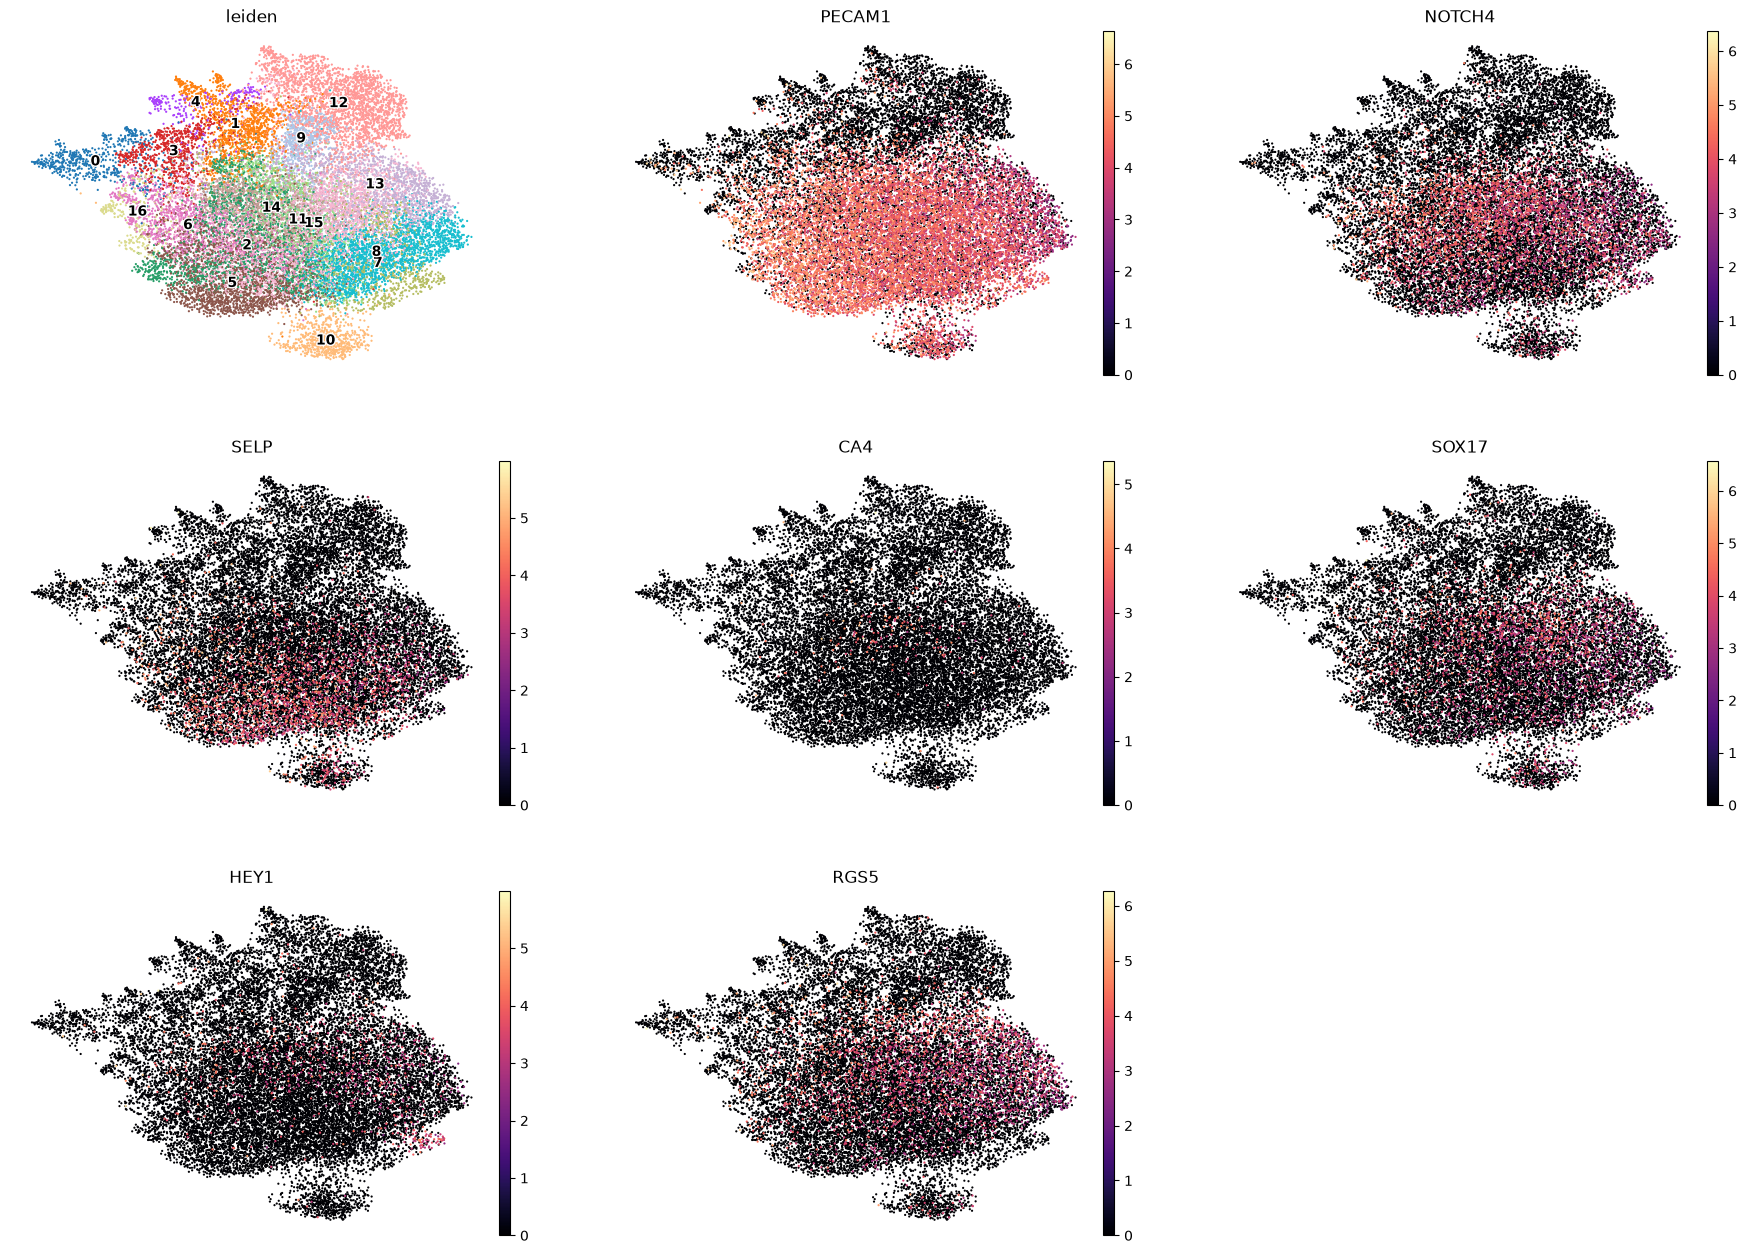

In [ ]:
genes_to_plot = ['PECAM1', 'NOTCH4', 'SELP', 'CA4', 'SOX17', 'HEY1', 'RGS5', 'MYH11']


genes_to_plot = [g for g in genes_to_plot if g in adata_endothelial.var_names]

plots_to_show = ["leiden"] + genes_to_plot

sc.pl.umap(
    adata_endothelial,
    color=plots_to_show,
    color_map="magma",
    ncols=3,
    size=10,
    frameon=False,
    legend_loc="on data",
    legend_fontoutline=2
)

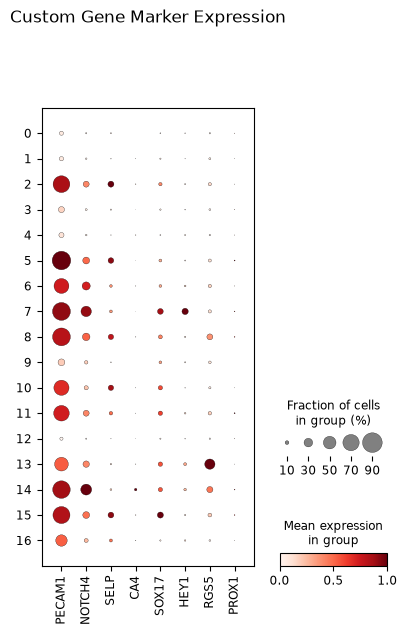

In [ ]:
my_genes = ['PECAM1', 'NOTCH4', 'SELP', 'CA4', 'SOX17', 'HEY1', 'RGS5', 'PROX1','RAMP3']

my_genes = [g for g in my_genes if g in adata_endothelial.var_names]

sc.pl.dotplot(
    adata_endothelial,
    var_names=my_genes,
    groupby="leiden",
    cmap="Reds",
    expression_cutoff=0.0,
    standard_scale="var",
    title="Custom Gene Marker Expression",
)

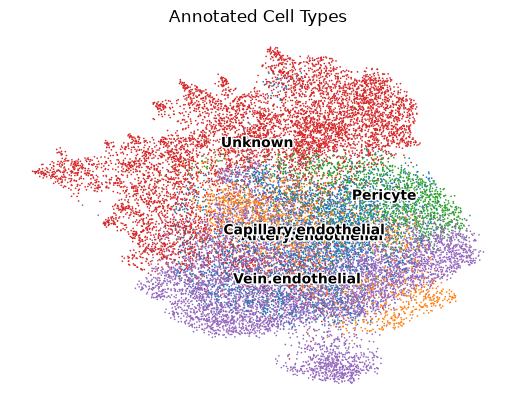

In [ ]:
cluster_to_celltype = {
    '0': 'Unknown',
    '1': 'Unknown',
    '2': 'Vein.endothelial',
    '3': 'Unknown',
    '4': 'Unknown',
    '5': 'Vein.endothelial',
    '6': 'Unknown',
    '7': 'Capillary.endothelial',
    '8': 'Vein.endothelial',
    '9': 'Unknown',
    '10': 'Vein.endothelial',
    '11': 'Artery.endothelial',
    '12': 'Unknown',
    '13': 'Pericyte',
    '14': 'Capillary.endothelial',
    '15': 'Artery.endothelial',
    '16': 'Unknown'

}

adata_endothelial.obs['cell_type'] = adata_endothelial.obs['leiden'].map(cluster_to_celltype)

adata_endothelial.obs['cell_type'] = adata_endothelial.obs['cell_type'].astype('category')

sc.pl.umap(
    adata_endothelial,
    color='cell_type',
    legend_loc='on data',
    legend_fontsize=10,
    legend_fontoutline=2,
    title='Annotated Cell Types',
    frameon=False
)

#### Transferring Cell Type Labels

In [ ]:
adata_merged.obs["cell_type"] = None

subsets = [adata_endocrine, adata_endothelial]

for sub in subsets:
    adata_merged.obs.loc[sub.obs_names, "cell_type"] = sub.obs["cell_type"]

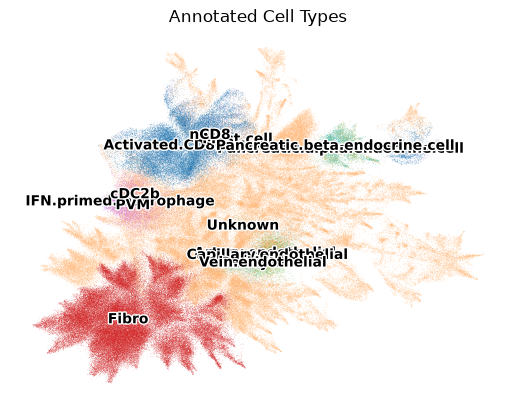

In [ ]:
sc.pl.umap(
    adata_merged,
    color='cell_type',
    legend_loc='on data',
    legend_fontsize=10,
    legend_fontoutline=2,
    title='Annotated Cell Types',
    frameon=False
)

#### Save Data

## SpatialDM - Ligand Receptor

In [ ]:
import spatialdm as sdm

SpatialDM version: 0.3.1


In [ ]:
df = pd.read_csv('PAAD_prioritized_permuted.csv', index_col = 0)

unique_combos = df[['ligand', 'receptor']].drop_duplicates()

print(unique_combos)

      ligand     receptor
1    TNFSF14     TNFRSF14
2       EREG         EGFR
3       TGFA         EGFR
4        TNC         EGFR
5      WNT5A         FZD6
8      LAMA3  ITGA1_ITGB1
10     LAMA3  ITGA6_ITGB1
12     LAMA3  ITGA6_ITGB4
14     LAMA3  ITGA9_ITGB1
16       TNC  ITGA9_ITGB1
17     WNT5A         LDLR
20       TNC         NT5E
21     WNT5A        PTPRK
24     WNT5A          RYK
27      AREG         EGFR
30     LAMA3         CD44
32      CDH1         EGFR
33      CDH1  ITGA1_ITGB1
34      CDH1  ITGA2_ITGB1
40     LAMA3  ITGA2_ITGB1
42       TNC        ITGA2
43     LAMA3  ITGA3_ITGB1
49       TNC  ITGA8_ITGB1
50       TNC  ITGAV_ITGB3
51     TIMP3       ADAM17
52    COL4A1         CD44
56     LAMC1         CD44
57      SPP1         CD44
59     TIMP3         CD44
60    COL4A1  ITGA1_ITGB1
62    COL4A1  ITGA3_ITGB1
66     LAMC1  ITGA1_ITGB1
69     LAMC1  ITGA3_ITGB1
70      SPP1  ITGAV_ITGB1
72      NID1        ITGAV
73  SERPINE1        ITGAV
74      NID1        ITGB1
75      TGM2

In [ ]:
gene_set = set(adata_merged.var_names)

def check_complex(gene_entry):
    subunits = str(gene_entry).split("_")
    return all(subunit in gene_set for subunit in subunits)

presence_df = unique_combos.map(check_complex)

presence_df["both_present"] = presence_df.all(axis=1)

print(
    f"Percentage of pairs fully present: {presence_df['both_present'].mean():.1%}"
)

Percentage of pairs fully present: 69.8%


In [ ]:
def run_sdm_pair(adata, ligand, receptor, n_perm=1000):
    pair = f"{ligand}_{receptor}"
    adata.uns['mean'] = 'geometric'

    adata.uns['geneInter'] = pd.DataFrame(
        {'ligand': [ligand], 'receptor': [receptor], 'annotation': ['Custom']},
        index=[pair]
    )

    ligand_genes = ligand.split('_')
    receptor_genes = receptor.split('_')

    ligand_dict = {f'Ligand{i+1}': gene for i, gene in enumerate(ligand_genes)}
    receptor_dict = {f'Receptor{i+1}': gene for i, gene in enumerate(receptor_genes)}

    adata.uns['ligand'] = pd.DataFrame([ligand_dict], index=[pair])
    adata.uns['receptor'] = pd.DataFrame([receptor_dict], index=[pair])

    adata.var_names_make_unique()

    if sp.issparse(adata.X):
        adata.X = adata.X.toarray()

    adata.raw = adata

    sdm.weight_matrix(adata, l=1.2, cutoff=0.2, single_cell=False)
    sdm.spatialdm_global(adata, n_perm=n_perm, specified_ind=[pair], method='permutation', nproc=1)
    sdm.spatialdm_local(adata, n_perm=n_perm, specified_ind=[pair], method='permutation', nproc=1)
    sdm.sig_spots(adata, method='permutation', fdr=False, threshold=0.05)

    adata.obs[f"{pair}_sig"] = adata.uns['selected_spots'].loc[pair].values.astype(str)
    return adata.uns['global_res'].loc[[pair]]

#### SpatialDM on All Interactions

In [ ]:
print("Pre-building sample-specific AnnData objects...")
sample_adatas = {}
sample_col_map = {}
unique_samples = adata_merged.obs['sample_id'].unique()

for sample in unique_samples:
    print(f"  └─ Preparing {sample}...", end="", flush=True)
    adata_sub = adata_merged[adata_merged.obs['sample_id'] == sample].copy()

    if sp.issparse(adata_sub.X):
        adata_sub.X = adata_sub.X.toarray()

    sample_adatas[sample] = adata_sub

    sample_col_map[sample] = f"{sample} pval"

    print(" Done!")


results_list = []
total_pairs = len(unique_combos)

for i, (_, row) in enumerate(unique_combos.iterrows(), start=1):
    ligand = str(row['ligand'])
    receptor = str(row['receptor'])

    print(f"[{i}/{total_pairs}] Processing pair: {ligand} -> {receptor}", flush=True)
    pair_summary = {'ligand': ligand, 'receptor': receptor}

    ligand_subunits = ligand.split('_')
    receptor_subunits = receptor.split('_')

    for sample, adata_base in sample_adatas.items():
        col_name = sample_col_map[sample]

        ligand_present = all(sub in adata_base.var_names for sub in ligand_subunits)
        receptor_present = all(sub in adata_base.var_names for sub in receptor_subunits)

        if not (ligand_present and receptor_present):
            pair_summary[col_name] = np.nan
            continue

        try:
            adata_sub = adata_base.copy()
            res = run_sdm_pair(adata_sub, ligand, receptor)
            pair_summary[col_name] = res['perm_pval'].values[0]
        except Exception:
            pair_summary[col_name] = np.nan

    results_list.append(pair_summary)


summary_df = pd.DataFrame(results_list)

base_cols = ['ligand', 'receptor']

pval_cols = sorted([sample_col_map[sample] for sample in unique_samples])

desired_order = base_cols + pval_cols

extra_cols = [c for c in summary_df.columns if c not in desired_order]
desired_order.extend(extra_cols)

summary_df = summary_df.reindex(columns=[c for c in desired_order if c in summary_df.columns])

print("\n================ FINAL RESULTS SUMMARY ================")
print(summary_df)

Pre-building sample-specific AnnData objects...
  └─ Preparing GSM9372001_Pt01... Done!
  └─ Preparing GSM9372003_Pt09... Done!
  └─ Preparing GSM9372002_Pt10... Done!
  └─ Preparing GSM9372004_Pt11... Done!
  └─ Preparing GSM9372005_Pt15... Done!
  └─ Preparing GSM9372006_Pt20... Done!
[1/43] Processing pair: TNFSF14 -> TNFRSF14


100%|██████████| 1000/1000 [00:01<00:00, 682.84it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:03<00:00, 264.96it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:05<00:00, 198.07it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:07<00:00, 126.72it/s]


[2/43] Processing pair: EREG -> EGFR


100%|██████████| 1000/1000 [00:01<00:00, 705.31it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:03<00:00, 274.01it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:04<00:00, 214.43it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:07<00:00, 138.12it/s]


[3/43] Processing pair: TGFA -> EGFR


...

[41/43] Processing pair: WNT5A -> ROR1


100%|██████████| 1000/1000 [00:01<00:00, 683.51it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:03<00:00, 257.58it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:04<00:00, 201.30it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:07<00:00, 127.87it/s]


[42/43] Processing pair: CDH1 -> PTPRF


100%|██████████| 1000/1000 [00:01<00:00, 698.95it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:03<00:00, 276.73it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:04<00:00, 207.71it/s]
C:\Users\jijeo\anaconda3\envs\Xenium\Lib\site-packages\spatialdm\utils.py:174: RuntimeWarning: invalid value encountered in divide
  X = X/X.max()
100%|██████████| 1000/1000 [00:07<00:00, 134.28it/s]


[43/43] Processing pair: DUSP18 -> ITGA7

================ FINAL RESULTS SUMMARY ================
      ligand     receptor  GSM9372001_Pt01 pval  GSM9372002_Pt10 pval  \
0    TNFSF14     TNFRSF14                 0.145                 0.352   
1       EREG         EGFR                 0.461                 0.205   
2       TGFA         EGFR                 0.825                 0.217   
3        TNC         EGFR                 0.432                 0.323   
4      WNT5A         FZD6                 0.126                 0.259   
5      LAMA3  ITGA1_ITGB1                 0.209                 0.185   
6      LAMA3  ITGA6_ITGB1                 0.048                 0.128   
7      LAMA3  ITGA6_ITGB4                 0.410                 0.078   
8      LAMA3  ITGA9_ITGB1                   NaN                   NaN   
9        TNC  ITGA9_ITGB1                   NaN                   NaN   
10     WNT5A         LDLR                 0.296                 0.116   
11       TNC         NT5E 

In [ ]:
# Define your significance threshold
alpha = 0.1

# Identify all columns that contain 'pval'
pval_cols = [col for col in summary_df.columns if 'pval' in col.lower()]

# Count how many of those columns are below the threshold for each row
summary_df['sig_patient_count'] = (summary_df[pval_cols] < alpha).sum(axis=1)

# Optional: Sort the dataframe so the pairs significant in the most patients are at the top
summary_df = summary_df.sort_values(by='sig_patient_count', ascending=False)

print(summary_df)

      ligand     receptor  GSM9372001_Pt01 pval  GSM9372002_Pt10 pval  \
41      CDH1        PTPRF                 0.095                 0.183   
30    COL4A1  ITGA3_ITGB1                 0.090                 0.028   
35  SERPINE1        ITGAV                 0.127                 0.616   
18      CDH1  ITGA2_ITGB1                 0.067                 0.150   
6      LAMA3  ITGA6_ITGB1                 0.048                 0.128   
21     LAMA3  ITGA3_ITGB1                 0.067                 0.186   
29    COL4A1  ITGA1_ITGB1                 0.044                 0.177   
7      LAMA3  ITGA6_ITGB4                 0.410                 0.078   
17      CDH1  ITGA1_ITGB1                 0.089                 0.170   
3        TNC         EGFR                 0.432                 0.323   
4      WNT5A         FZD6                 0.126                 0.259   
19     LAMA3  ITGA2_ITGB1                 0.240                 0.212   
25    COL4A1         CD44                 0.739    

In [ ]:
summary_df.to_csv("all_spatialdm_lr_pairs_summary.csv", index=False)

#### Colocalization on All Interactions

In [ ]:
ligand_col = next(c for c in unique_combos.columns if 'ligand' in c.lower())
receptor_col = next(c for c in unique_combos.columns if 'receptor' in c.lower())

def get_presence(adata, gene_str):
    mask = np.ones(adata.n_obs, dtype=bool)
    for g in gene_str.split('_'):
        g_col = adata[:, g].X
        if sp.issparse(g_col):
            g_col = g_col.toarray()
        mask &= (g_col.flatten() > 0)
    return mask

total_pairs = len(unique_combos)
samples = adata_merged.obs['sample_id'].unique()[:6]

for i, (_, row) in enumerate(unique_combos.iterrows(), start=1):
    ligand, receptor = str(row[ligand_col]), str(row[receptor_col])

    if not all(g in adata_merged.var_names for g in ligand.split('_') + receptor.split('_')):
        print(f"[{i}/{total_pairs}] Skipped {ligand}_{receptor} (genes missing)")
        continue

    print(f"[{i}/{total_pairs}] Plotting {ligand}_{receptor}...")

    l_pres = get_presence(adata_merged, ligand)
    r_pres = get_presence(adata_merged, receptor)

    lbl_L = f"{ligand} Only"
    lbl_R = f"{receptor} Only"

    conditions = [l_pres & r_pres, l_pres & ~r_pres, ~l_pres & r_pres]
    choices = ["Both", lbl_L, lbl_R]

    adata_merged.obs['plot_group'] = pd.Categorical(
        np.select(conditions, choices, default="Neither"),
        categories=["Neither", lbl_L, lbl_R, "Both"],
        ordered=True
    )

    color_map = {"Neither": "#e0e0e0", lbl_L: "#E41A1C", lbl_R: "#377EB8", "Both": "#984EA3"}

    fig, axes = plt.subplots(2, 3, figsize=(30, 14))
    axes = axes.flatten()

    for idx, sample in enumerate(samples):
        adata_sample = adata_merged[adata_merged.obs['sample_id'] == sample]
        adata_sample = adata_sample[adata_sample.obs['plot_group'].argsort()].copy()

        sc.pl.embedding(
            adata_sample,
            basis="spatial",
            color="plot_group",
            palette=color_map,
            ax=axes[idx],
            show=False,
            title=f"Sample: {sample}",
            frameon=False,
            size=10,
            sort_order=False
        )
        axes[idx].set(xlabel="", ylabel="")

    for ax in axes[len(samples):]:
        ax.axis('off')

    plt.subplots_adjust(wspace=0.3, hspace=0.3)

    safe_filename = f"{ligand}_{receptor}_expression.pdf".replace("/", "-")
    plt.savefig(safe_filename, dpi=300, bbox_inches="tight")
    plt.close(fig)

[1/43] Plotting TNFSF14_TNFRSF14...
[2/43] Plotting EREG_EGFR...
[3/43] Plotting TGFA_EGFR...
[4/43] Plotting TNC_EGFR...
[5/43] Plotting WNT5A_FZD6...
[6/43] Plotting LAMA3_ITGA1_ITGB1...
[7/43] Plotting LAMA3_ITGA6_ITGB1...
[8/43] Plotting LAMA3_ITGA6_ITGB4...
[9/43] Skipped LAMA3_ITGA9_ITGB1 (genes missing)
[10/43] Skipped TNC_ITGA9_ITGB1 (genes missing)
[11/43] Plotting WNT5A_LDLR...
[12/43] Plotting TNC_NT5E...
[13/43] Skipped WNT5A_PTPRK (genes missing)
[14/43] Skipped WNT5A_RYK (genes missing)
[15/43] Skipped AREG_EGFR (genes missing)
[16/43] Plotting LAMA3_CD44...
[17/43] Plotting CDH1_EGFR...
[18/43] Plotting CDH1_ITGA1_ITGB1...
[19/43] Plotting CDH1_ITGA2_ITGB1...
[20/43] Plotting LAMA3_ITGA2_ITGB1...
[21/43] Plotting TNC_ITGA2...
[22/43] Plotting LAMA3_ITGA3_ITGB1...
[23/43] Skipped TNC_ITGA8_ITGB1 (genes missing)
[24/43] Plotting TNC_ITGAV_ITGB3...
[25/43] Skipped TIMP3_ADAM17 (genes missing)
[26/43] Plotting COL4A1_CD44...
[27/43] Plotting LAMC1_CD44...
[28/43] Skipped SPP